In [1]:
%pip install pandas requests matplotlib

import requests
import pandas as pd
import matplotlib.pyplot as plt
import time
import json
import re

from datetime import datetime, timedelta, timezone

Defaulting to user installation because normal site-packages is not writeable

[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [2]:
GAMES = {
    "Cyberpunk 2077": 1091500,
    "No Man's Sky": 275850,
    "Helldivers 2": 553850,
    "Elden Ring": 1245620
}

GAME = "Cyberpunk 2077"
APP_ID = GAMES[GAME]

WINDOW_DAYS = 14

print(f"Selected game: {GAME}")
print(f"Steam App ID: {APP_ID}")

Selected game: Cyberpunk 2077
Steam App ID: 1091500


In [3]:
# Collect update news that looks patch related

NEWS_URL = "https://api.steampowered.com/ISteamNews/GetNewsForApp/v2/"
REVIEWS_URL = "https://api.steampowered.com/IUserReviewsService/GetAppReviews/v1/"

session = requests.Session()

# returns json format of requested url api request
def get_json(url, params):
    for attempt in range(4):
        response = session.get(url, params=params, timeout=30)

        if response.status_code in [429, 500, 502, 503, 504]:
            if attempt == 3:
                response.raise_for_status()

            wait = min(60, 5 * (2 ** attempt))
            time.sleep(wait)
            continue

        response.raise_for_status()
        return response.json()


#scrapes the pages for news, finds update/patch related announcements
def get_patch_news(app_id, max_pages=3):
    news = []
    enddate = None

    for page in range(max_pages):
        params = {
            "appid": app_id,
            "count": 100,
            "maxlength": 1000
        }

        if enddate is not None:
            params["enddate"] = enddate

        data = get_json(NEWS_URL, params)
        batch = data.get("appnews", {}).get("newsitems", [])

        if not batch:
            break

        news.extend(batch)
        enddate = min(item["date"] for item in batch) - 1

        time.sleep(1.5)

    df = pd.DataFrame(news)

    if df.empty:
        return df

    df = df.drop_duplicates(subset="gid")

    df["date"] = pd.to_datetime(
        df["date"], unit="s", utc=True
    )

    # Find announcements that might be patches
    pattern = r"\b(patch|hotfix|update|fixes|changelog)\b"

    df["is_patch_candidate"] = df["title"].str.contains(
        pattern, case=False, regex=True, na=False
    )

    return df.sort_values("date", ascending=False)

In [4]:
patches_df = get_patch_news(APP_ID)

patch_candidates = patches_df[
    patches_df["is_patch_candidate"]
]

display(patch_candidates[["date", "title", "url"]].head(25))

patches_df.to_csv("cyberpunk_news.csv", index=False)

/tmp/ipykernel_1222802/2810395493.py:65: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  df["is_patch_candidate"] = df["title"].str.contains(


,date,title,url
29,2026-10-22 10:12:54+00:00,Cyberpunk 2077 Edgerunners update brings impro...,https://steamstore-a.akamaihd.net/news/externa...
30,2026-10-22 10:06:54+00:00,Cyberpunk 2077's Edgerunners 2 Update (2.5) is...,https://steamstore-a.akamaihd.net/news/externa...
33,2026-10-21 16:09:58+00:00,Cyberpunk 2077's Edgerunners 2 update adds two...,https://steamstore-a.akamaihd.net/news/externa...
37,2026-10-21 15:45:15+00:00,Check out what's coming to Cyberpunk 2077 in t...,https://steamstore-a.akamaihd.net/news/externa...
43,2026-10-20 10:00:33+00:00,REDstreams — Cyberpunk 2077: Edgerunners 2 Upd...,https://steamstore-a.akamaihd.net/news/externa...
147,2025-09-11 14:58:15+00:00,CDPR returns to the fridge for one more Cyberp...,https://steamstore-a.akamaihd.net/news/externa...
148,2025-09-11 10:09:03+00:00,Patch 2.31,https://steamstore-a.akamaihd.net/news/externa...
161,2025-07-16 17:52:27+00:00,Seven months after putting Johnny Silverhand i...,https://steamstore-a.akamaihd.net/news/externa...
162,2025-07-16 16:12:59+00:00,Cyberpunk 2077 update 2.3 motors into your lif...,https://steamstore-a.akamaihd.net/news/externa...
163,2025-07-16 16:12:38+00:00,Update 2.3 Patch Notes,https://steamstore-a.akamaihd.net/news/externa...


In [5]:
# Collect steam reviews within a start and end date
def get_reviews(app_id, start_date, end_date,
                max_pages=3, language="english"):

    reviews = []
    cursor = "*"
    seen_cursors = set()
    page = 0

    start_ts = int(pd.Timestamp(start_date).timestamp())
    end_ts = int(pd.Timestamp(end_date).timestamp())

    while max_pages is None or page < max_pages:

        if cursor in seen_cursors:
            break

        seen_cursors.add(cursor)

        query = {
            "appid": app_id,
            "filter": 1,              # Newest created first
            "languages": [language],
            "review_type": 0,         # Positive and negative
            "purchase_type": 1,       # All purchase types
            "num_per_page": 100,
            "cursor": cursor,
            "date_range_start": start_ts,
            "date_range_end": end_ts,
            "filter_offtopic_activity": False
        }

        data = get_json(
            REVIEWS_URL,
            {"input_json": json.dumps(query)}
        )

        result = data.get("response", data)
        batch = result.get("reviews", [])

        if not batch:
            break

        reviews.extend(batch)
        page += 1

        print(f"Page {page}: {len(reviews)} reviews collected")

        next_cursor = result.get("cursor")

        if not next_cursor or next_cursor == cursor:
            break

        cursor = next_cursor
        time.sleep(1.5)

    rows = []

    for review in reviews:
        author = review.get("author", {})

        rows.append({
            "review_id": review.get("recommendationid"),
            "date": pd.to_datetime(
                review["timestamp_created"], unit="s", utc=True
            ),
            "updated_date": pd.to_datetime(
                review["timestamp_updated"], unit="s", utc=True
            ),
            "positive": review.get("voted_up"),
            "review_text": review.get("review"),
            "language": review.get("language"),
            "playtime_hours": (
                author.get("playtime_at_review", 0) / 60
            ),
            "helpful_votes": review.get("votes_up"),
            "steam_purchase": review.get("steam_purchase")
        })

    return pd.DataFrame(rows).drop_duplicates(
        subset="review_id"
    ) if rows else pd.DataFrame()

In [6]:
# Select a patch with a complete 14-day follow-up period

cutoff = pd.Timestamp.now(tz="UTC") - pd.Timedelta(
    days=WINDOW_DAYS
)

eligible = patch_candidates[
    patch_candidates["date"] < cutoff
]

selected_patch = eligible.iloc[0]

patch_date = selected_patch["date"]

print("Selected patch:", selected_patch["title"])
print("Patch announcement date:", patch_date)
print("URL:", selected_patch["url"])

Selected patch: Cyberpunk 2077 Edgerunners update brings improved modding, better HDR, new content and more
Patch announcement date: 2026-10-22 10:12:54+00:00
URL: https://steamstore-a.akamaihd.net/news/externalpost/GamingOnLinux/1847286114032050


In [7]:
# collect reviews around the patch - before and after
before_start = patch_date - pd.Timedelta(days=WINDOW_DAYS)
before_end = patch_date - pd.Timedelta(seconds=1)

after_start = patch_date
after_end = patch_date + pd.Timedelta(days=WINDOW_DAYS) - pd.Timedelta(seconds=1)

print("Collecting BEFORE patch reviews...")

before = get_reviews(
    APP_ID, before_start, before_end, max_pages=3
)

print("\nCollecting AFTER patch reviews...")

after = get_reviews(
    APP_ID, after_start, after_end, max_pages=3
)

before["period"] = "Before"
after["period"] = "After"

reviews_df = pd.concat(
    [before, after], ignore_index=True
)

reviews_df["game"] = GAME
reviews_df["patch_title"] = selected_patch["title"]
reviews_df["patch_date"] = patch_date

reviews_df.to_csv(
    "cyberpunk_patch_reviews.csv", index=False
)

print(f"\nTotal reviews collected: {len(reviews_df)}")

display(reviews_df.head())

Page 1: 100 reviews collected
Page 2: 200 reviews collected
Page 3: 300 reviews collected

Page 1: 100 reviews collected
Page 2: 200 reviews collected
Page 3: 287 reviews collected

Total reviews collected: 587


,review_id,date,updated_date,positive,review_text,language,playtime_hours,helpful_votes,steam_purchase,period,game,patch_title,patch_date
0,238293746,2026-10-22 10:11:37+00:00,2026-10-22 10:11:37+00:00,True,sigma sigma boi,english,258.266667,1,True,Before,Cyberpunk 2077,Cyberpunk 2077 Edgerunners update brings impro...,2026-10-22 10:12:54+00:00
1,238293603,2026-10-22 10:08:00+00:00,2026-10-22 10:08:00+00:00,True,its fun love the boobs,english,38.733333,2,True,Before,Cyberpunk 2077,Cyberpunk 2077 Edgerunners update brings impro...,2026-10-22 10:12:54+00:00
2,238293553,2026-10-22 10:06:59+00:00,2026-10-22 10:06:59+00:00,True,David Martinez the goat,english,106.916667,0,True,Before,Cyberpunk 2077,Cyberpunk 2077 Edgerunners update brings impro...,2026-10-22 10:12:54+00:00
3,238293527,2026-10-22 10:06:23+00:00,2026-10-22 10:06:23+00:00,True,"peak, mods can allow you to use ai voice mods,...",english,109.733333,0,True,Before,Cyberpunk 2077,Cyberpunk 2077 Edgerunners update brings impro...,2026-10-22 10:12:54+00:00
4,238293445,2026-10-22 10:04:06+00:00,2026-10-22 10:04:06+00:00,True,peak,english,251.283333,0,True,Before,Cyberpunk 2077,Cyberpunk 2077 Edgerunners update brings impro...,2026-10-22 10:12:54+00:00


In [8]:
# summerize findings 
summary = reviews_df.groupby("period").agg(
    total_reviews=("positive", "count"),
    positive_rate=("positive", "mean")
)

summary["positive_percent"] = (
    summary["positive_rate"] * 100
)

display(summary)

,total_reviews,positive_rate,positive_percent
period,,,
After,287,0.951220,95.121951
Before,300,0.966667,96.666667


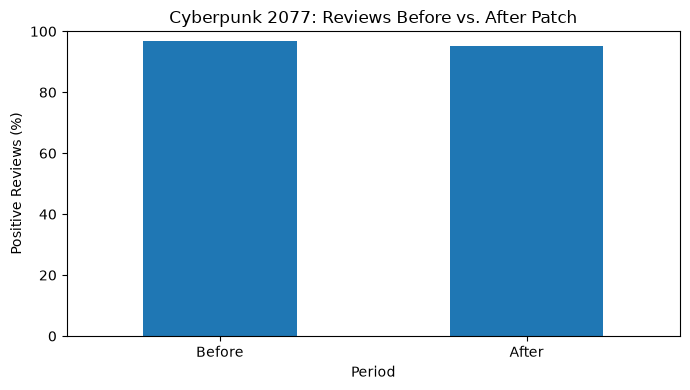

In [9]:
summary = summary.reindex(["Before", "After"])

summary["positive_percent"].plot(
    kind="bar",
    figsize=(7, 4)
)

plt.title(f"{GAME}: Reviews Before vs. After Patch")
plt.ylabel("Positive Reviews (%)")
plt.xlabel("Period")
plt.ylim(0, 100)
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [10]:
# Settings for the multi-game run
PATCHES_PER_GAME = 3      # most recent official patches per game to analyze
NEWS_PAGES = 5            # pages of news (100 posts each) per game
PAGES_PER_DAY = 1         # review pages (100 reviews each) per day of each window
SAME_UPDATE_DAYS = 3      # posts closer together than this count as one update

TEASER_PATTERN = r"\b(?:coming|delayed|delay|preview|stream|redstreams|teaser|roadmap|sneak peek)\b"


def official_patches(news_df):
    """Keep the developer's own patch announcements and one per update."""
    if news_df.empty:
        return news_df

    df = news_df[news_df["is_patch_candidate"]].copy()

    # Official Steam announcements only (not press articles)
    if "feedname" in df.columns:
        official = df[df["feedname"] == "steam_community_announcements"]
        if not official.empty:
            df = official

    # Drop teaser / preview posts
    df = df[~df["title"].str.contains(TEASER_PATTERN, case=False, regex=True, na=False)]

    # Several posts about the same update -> keep the first one
    df = df.sort_values("date")
    gaps = df["date"].diff()
    df = df[gaps.isna() | (gaps > pd.Timedelta(days=SAME_UPDATE_DAYS))]

    return df.sort_values("date", ascending=False)

## Collect news for every game

In [11]:
all_news = []

for game, app_id in GAMES.items():
    print(f"Collecting news for {game} ({app_id})...")
    try:
        news = get_patch_news(app_id, max_pages=NEWS_PAGES)
    except Exception as e:
        print("  failed:", e)
        continue
    news["game"] = game
    news["app_id"] = app_id
    all_news.append(news)
    print(f"  {len(news)} posts, {news['is_patch_candidate'].sum()} patch candidates")
    time.sleep(1.5)

all_news_df = pd.concat(all_news, ignore_index=True)
all_news_df.to_csv("all_games_news.csv", index=False)

/tmp/ipykernel_1222802/2810395493.py:65: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  df["is_patch_candidate"] = df["title"].str.contains(


  500 posts, 53 patch candidates


/tmp/ipykernel_1222802/2810395493.py:65: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  df["is_patch_candidate"] = df["title"].str.contains(


  500 posts, 168 patch candidates


/tmp/ipykernel_1222802/2810395493.py:65: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  df["is_patch_candidate"] = df["title"].str.contains(


  500 posts, 136 patch candidates


/tmp/ipykernel_1222802/2810395493.py:65: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  df["is_patch_candidate"] = df["title"].str.contains(


  500 posts, 38 patch candidates


## Pick official patches for each game
Only patches with a full 14-day follow-up period are eligible. 


In [12]:
cutoff = pd.Timestamp.now(tz="UTC") - pd.Timedelta(days=WINDOW_DAYS)

selected = []
for game, news in all_news_df.groupby("game"):
    patches = official_patches(news)
    patches = patches[patches["date"] < cutoff].head(PATCHES_PER_GAME)
    selected.append(patches)

selected_patches = pd.concat(selected, ignore_index=True)
selected_patches = selected_patches.sort_values(["game", "date"])

display(selected_patches[["game", "date", "title", "url"]])

,game,date,title,url
2,Cyberpunk 2077,2025-07-16 16:12:38+00:00,Update 2.3 Patch Notes,https://steamstore-a.akamaihd.net/news/externa...
1,Cyberpunk 2077,2025-09-11 10:09:03+00:00,Patch 2.31,https://steamstore-a.akamaihd.net/news/externa...
0,Cyberpunk 2077,2026-10-22 10:06:54+00:00,Cyberpunk 2077's Edgerunners 2 Update (2.5) is...,https://steamstore-a.akamaihd.net/news/externa...
5,Elden Ring,2024-10-17 07:40:57+00:00,Patch Notes Version 1.16,https://steamstore-a.akamaihd.net/news/externa...
4,Elden Ring,2025-08-21 12:09:05+00:00,ELDEN RING - Patch Notes Version 1.16.1,https://steamstore-a.akamaihd.net/news/externa...
3,Elden Ring,2026-08-27 14:00:22+00:00,Patch Notes Version 1.17,https://steamstore-a.akamaihd.net/news/externa...
8,Helldivers 2,2025-09-24 13:02:01+00:00,State of the Game Update #1,https://steamstore-a.akamaihd.net/news/externa...
7,Helldivers 2,2026-05-21 12:02:35+00:00,Optimizing Liberty - Incoming Patch: 27th May,https://steamstore-a.akamaihd.net/news/externa...
6,Helldivers 2,2026-08-12 12:05:35+00:00,HELLDIVERS 2 Devoid of Liberty Update Out Now,https://steamstore-a.akamaihd.net/news/externa...
11,No Man's Sky,2023-04-05 16:47:47+00:00,Introducing...the INTERCEPTOR Update,https://steamstore-a.akamaihd.net/news/externa...


## Collect reviews before and after each patch
One request batch per day of each window, so all 14 days on each side are sampled. With the defaults this is about 28 requests per patch

In [13]:
def get_reviews_by_day(app_id, start, end, pages_per_day=1):
    """Call get_reviews once per day so the whole window is sampled."""
    days = []
    day_start = start
    while day_start < end:
        day_end = min(day_start + pd.Timedelta(days=1), end) - pd.Timedelta(seconds=1)
        day = get_reviews(app_id, day_start, day_end, max_pages=pages_per_day)
        if not day.empty:
            days.append(day)
        day_start = day_start + pd.Timedelta(days=1)
        time.sleep(1.5)
    return pd.concat(days, ignore_index=True) if days else pd.DataFrame()


all_reviews = []

for _, patch in selected_patches.iterrows():
    game, app_id, p_date = patch["game"], patch["app_id"], patch["date"]
    print(f"\n=== {game}: {patch['title']} ({p_date.date()}) ===")

    try:
        before = get_reviews_by_day(app_id, p_date - pd.Timedelta(days=WINDOW_DAYS),
                                    p_date, PAGES_PER_DAY)
        after = get_reviews_by_day(app_id, p_date,
                                   p_date + pd.Timedelta(days=WINDOW_DAYS), PAGES_PER_DAY)
    except Exception as e:
        print("  failed:", e)
        continue

    for part, label in [(before, "Before"), (after, "After")]:
        if part.empty:
            continue
        part["period"] = label
        part["game"] = game
        part["app_id"] = app_id
        part["patch_title"] = patch["title"]
        part["patch_date"] = p_date
        all_reviews.append(part)

all_reviews_df = pd.concat(all_reviews, ignore_index=True)
all_reviews_df = all_reviews_df.drop_duplicates(subset=["review_id", "patch_date"])
all_reviews_df.to_csv("all_games_patch_reviews.csv", index=False)

print(f"\nTotal reviews collected: {len(all_reviews_df)}")


=== Cyberpunk 2077: Update 2.3 Patch Notes (2025-07-16) ===
Page 1: 100 reviews collected
Page 1: 100 reviews collected
Page 1: 100 reviews collected
Page 1: 100 reviews collected
Page 1: 100 reviews collected
Page 1: 100 reviews collected
Page 1: 100 reviews collected
Page 1: 100 reviews collected
Page 1: 100 reviews collected
Page 1: 100 reviews collected
Page 1: 100 reviews collected
Page 1: 100 reviews collected
Page 1: 100 reviews collected
Page 1: 100 reviews collected
Page 1: 100 reviews collected
Page 1: 100 reviews collected
Page 1: 100 reviews collected
Page 1: 100 reviews collected
Page 1: 100 reviews collected
Page 1: 100 reviews collected
Page 1: 100 reviews collected
Page 1: 100 reviews collected
Page 1: 100 reviews collected
Page 1: 100 reviews collected
Page 1: 100 reviews collected
Page 1: 100 reviews collected
Page 1: 100 reviews collected
Page 1: 100 reviews collected

=== Cyberpunk 2077: Patch 2.31 (2025-09-11) ===
Page 1: 100 reviews collected
Page 1: 100 reviews 

## Before vs. after for every patch

In [14]:
patch_summary = (
    all_reviews_df
    .groupby(["game", "patch_date", "patch_title", "period"])["positive"]
    .agg(reviews="count", positive_percent=lambda s: s.mean() * 100)
    .unstack("period")
)
patch_summary.columns = [f"{stat}_{period.lower()}" for stat, period in patch_summary.columns]
patch_summary["change_points"] = (
    patch_summary["positive_percent_after"] - patch_summary["positive_percent_before"]
)
patch_summary = patch_summary.reset_index().sort_values(["game", "patch_date"])

display(patch_summary.round({c: 1 for c in patch_summary.select_dtypes("number").columns}))
patch_summary.to_csv("all_games_patch_summary.csv", index=False)

,game,patch_date,patch_title,reviews_after,reviews_before,positive_percent_after,positive_percent_before,change_points
0,Cyberpunk 2077,2025-07-16 16:12:38+00:00,Update 2.3 Patch Notes,1400,1400,94.2,95.1,-0.9
1,Cyberpunk 2077,2025-09-11 10:09:03+00:00,Patch 2.31,1363,1390,94.0,95.3,-1.3
2,Cyberpunk 2077,2026-10-22 10:06:54+00:00,Cyberpunk 2077's Edgerunners 2 Update (2.5) is...,1400,1400,95.1,96.1,-1.0
3,Elden Ring,2024-10-17 07:40:57+00:00,Patch Notes Version 1.16,1381,1400,93.5,95.3,-1.8
4,Elden Ring,2025-08-21 12:09:05+00:00,ELDEN RING - Patch Notes Version 1.16.1,1240,1375,94.4,94.0,0.5
5,Elden Ring,2026-08-27 14:00:22+00:00,Patch Notes Version 1.17,1386,1133,82.8,94.1,-11.3
6,Helldivers 2,2025-09-24 13:02:01+00:00,State of the Game Update #1,1398,1400,67.5,65.1,2.5
7,Helldivers 2,2026-05-21 12:02:35+00:00,Optimizing Liberty - Incoming Patch: 27th May,1398,1400,65.1,48.9,16.2
8,Helldivers 2,2026-08-12 12:05:35+00:00,HELLDIVERS 2 Devoid of Liberty Update Out Now,1400,1225,82.2,80.7,1.6
9,No Man's Sky,2023-04-05 16:47:47+00:00,Introducing...the INTERCEPTOR Update,988,386,91.2,90.9,0.3


In [15]:
# Average change per game
game_summary = patch_summary.groupby("game").agg(
    patches=("patch_title", "count"),
    avg_before=("positive_percent_before", "mean"),
    avg_after=("positive_percent_after", "mean"),
    avg_change=("change_points", "mean"),
    patches_that_helped=("change_points", lambda s: (s > 0).sum()),
)
display(game_summary.round(1))

,patches,avg_before,avg_after,avg_change,patches_that_helped
game,,,,,
Cyberpunk 2077,3,95.5,94.4,-1.1,0
Elden Ring,3,94.4,90.2,-4.2,1
Helldivers 2,3,64.9,71.6,6.7,3
No Man's Sky,3,91.3,91.0,-0.4,2


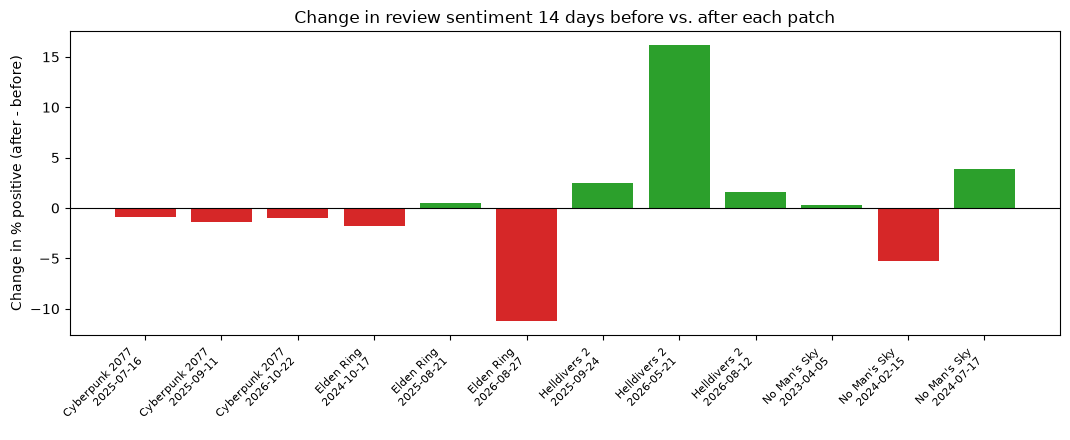

In [16]:
# Chart: change in % positive for each patch, grouped by game
plot_df = patch_summary.copy()
plot_df["label"] = plot_df["game"] + "\n" + plot_df["patch_date"].dt.strftime("%Y-%m-%d")
colors = ["tab:green" if c > 0 else "tab:red" for c in plot_df["change_points"]]

fig, ax = plt.subplots(figsize=(max(8, len(plot_df) * 0.9), 4.5))
ax.bar(plot_df["label"], plot_df["change_points"], color=colors)
ax.axhline(0, color="black", linewidth=0.8)
ax.set_ylabel("Change in % positive (after - before)")
ax.set_title(f"Change in review sentiment {WINDOW_DAYS} days before vs. after each patch")
plt.xticks(rotation=45, ha="right", fontsize=8)
plt.tight_layout()
plt.show()

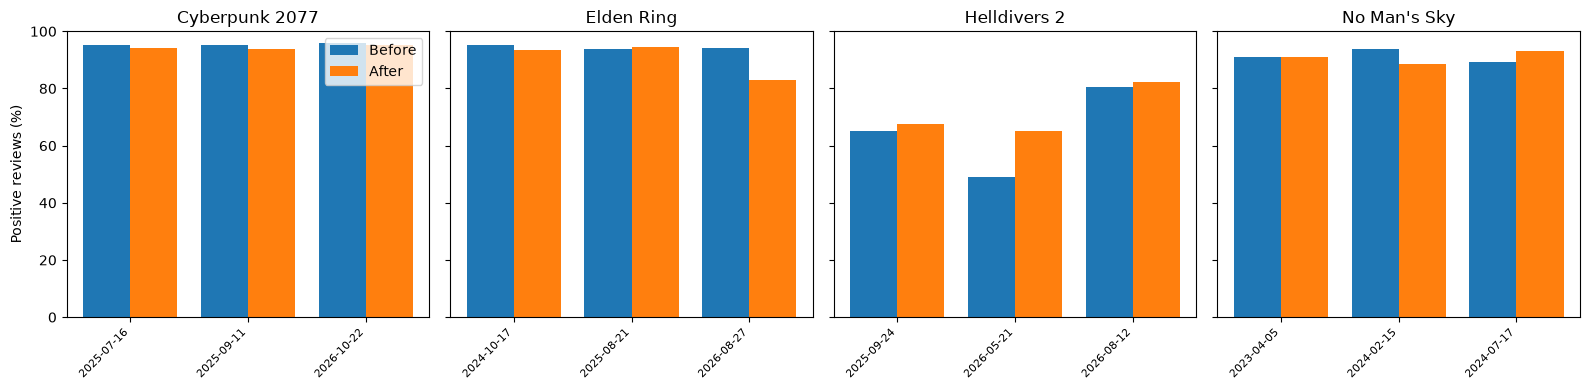

In [17]:
# Chart: before vs. after side by side for each game's patches
games_list = list(patch_summary["game"].unique())
fig, axes = plt.subplots(1, len(games_list), figsize=(4 * len(games_list), 4), sharey=True)
if len(games_list) == 1:
    axes = [axes]

for ax, game in zip(axes, games_list):
    g = patch_summary[patch_summary["game"] == game]
    x = range(len(g))
    ax.bar([i - 0.2 for i in x], g["positive_percent_before"], width=0.4, label="Before")
    ax.bar([i + 0.2 for i in x], g["positive_percent_after"], width=0.4, label="After")
    ax.set_xticks(list(x))
    ax.set_xticklabels(g["patch_date"].dt.strftime("%Y-%m-%d"), rotation=45, ha="right", fontsize=8)
    ax.set_title(game)
    ax.set_ylim(0, 100)

axes[0].set_ylabel("Positive reviews (%)")
axes[0].legend()
plt.tight_layout()
plt.show()

## Long-term review history for every game

In [18]:
HISTOGRAM_URL = "https://store.steampowered.com/appreviewhistogram/{}"


def get_review_history(app_id):
    data = get_json(HISTOGRAM_URL.format(app_id), {"l": "english"})
    results = data.get("results") or {}
    df = pd.DataFrame(results.get("rollups", []))
    if df.empty:
        return df
    df = df.rename(columns={"recommendations_up": "up", "recommendations_down": "down"})
    df["date"] = pd.to_datetime(df["date"], unit="s", utc=True)
    df["granularity"] = results.get("rollup_type")
    df["positive_percent"] = df["up"] / (df["up"] + df["down"]) * 100
    return df


history = []
for game, app_id in GAMES.items():
    print(f"Review history for {game}...")
    try:
        h = get_review_history(app_id)
    except Exception as e:
        print("  failed:", e)
        continue
    h["game"] = game
    history.append(h)
    time.sleep(1.5)

history_df = pd.concat(history, ignore_index=True)
history_df.to_csv("all_games_review_history.csv", index=False)
display(history_df.groupby("game").agg(
    periods=("date", "count"), granularity=("granularity", "first"),
    first=("date", "min"), last=("date", "max"),
    total_reviews=("up", lambda s: s.sum() + history_df.loc[s.index, "down"].sum()),
))

Review history for Cyberpunk 2077...
Review history for No Man's Sky...
Review history for Helldivers 2...
Review history for Elden Ring...


,periods,granularity,first,last,total_reviews
game,,,,,
Cyberpunk 2077,72,month,2020-12-01 00:00:00+00:00,2026-11-01 00:00:00+00:00,968532
Elden Ring,58,month,2022-02-01 00:00:00+00:00,2026-11-01 00:00:00+00:00,887053
Helldivers 2,34,month,2024-02-01 00:00:00+00:00,2026-11-01 00:00:00+00:00,916895
No Man's Sky,124,month,2016-08-01 00:00:00+00:00,2026-11-01 00:00:00+00:00,335000


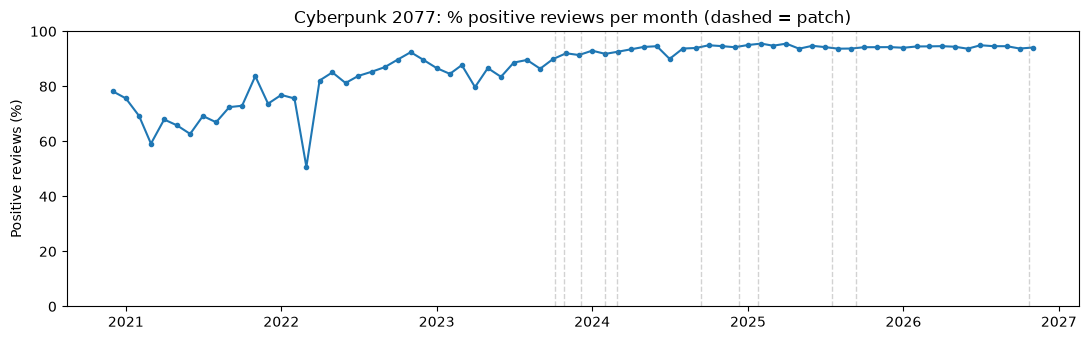

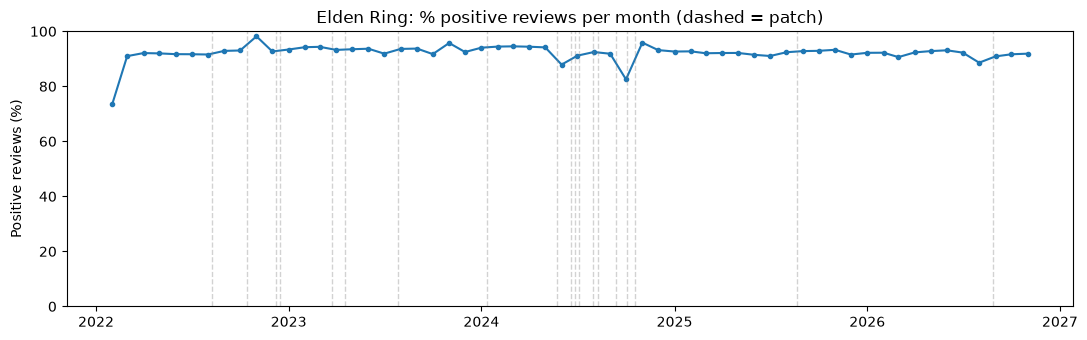

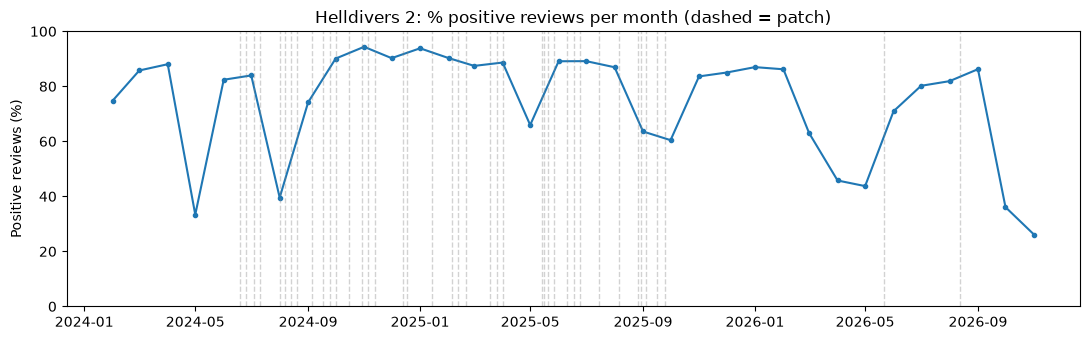

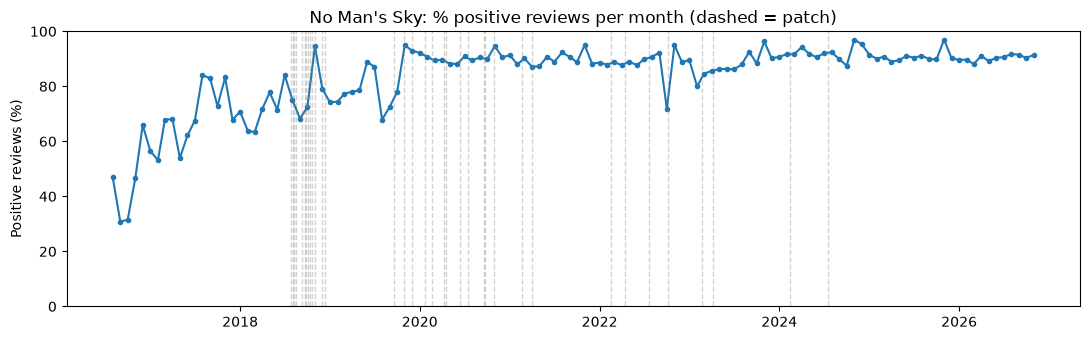

In [19]:
# Timeline chart per game: % positive over time, official patches as dashed lines
for game, h in history_df.groupby("game"):
    h = h.sort_values("date")
    fig, ax = plt.subplots(figsize=(11, 3.5))
    ax.plot(h["date"], h["positive_percent"], marker="o", markersize=3)

    official = official_patches(all_news_df[all_news_df["game"] == game])
    for d in official["date"]:
        ax.axvline(d, color="gray", linestyle="--", alpha=0.35, linewidth=1)

    ax.set_title(f"{game}: % positive reviews per {h['granularity'].iloc[0]} (dashed = patch)")
    ax.set_ylabel("Positive reviews (%)")
    ax.set_ylim(0, 100)
    plt.tight_layout()
    plt.show()